# Math Modeling: Intro to Data Analysis




## Review of Pandas

Pandas is a Python library that helps organize and analyze data efficiently.  
You can use it to:
- Load, filter, and clean datasets  
- Calculate statistics quickly  
- Create visualizations to summarize trends  

Run the code below to import your libraries.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Set up display options for readability
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 2)

**Some useful functions:**  
`pd.query`: Allows you to filter rows of a DataFrame based on a boolean expression provided as a string. 
Example usage: df.query('column_name > value') gives you the rows that have column_name > value

`pd.nlargest`: Returns the first n rows with the largest values in columns, in descending order.
Example usage: df.nlargest(3, 'population') gives you the 3 rows with the largest population.

Note: This function cannot be used with all column types. For example, when specifying columns with object or category dtypes, TypeError is raised.

`pd.describe`: Descriptive statistics include those that summarize the central tendency, dispersion and shape of a dataset’s distribution, excluding NaN values.

Example usage: df.describe() gives output   

        numeric
count      3.0
mean       2.0
std        1.0
min        1.0
25%        1.5
50%        2.0
75%        2.5
max        3.0

Note: to describe all columns of a dataframe regardless of their type set include='all'

Link to pandas documentation where you can find all sorts of methods: https://pandas.pydata.org/docs/reference/frame.html

## What is Data Analysis?

Data analysis helps you **make sense of raw information** to answer questions or make predictions.

**Pros:**
- Helps identify patterns that are not immediately apparent to the "naked eye"
- Supports evidence-based decisions  

**Cons:**
- Can be misleading if data is incomplete or inconsistent 
    - Common misconception: Just because two variables are shown to have a correlation, that does not necessarily mean one causes the other
        - Further testing would be needed to distinguish correlation from causation
- Requires clean and reliable input
    - Data sources should be known
    - Be mindful of missing values and have a strategy to handle them

If data analyis is not well thought out we can end up with ridiculous results like this:
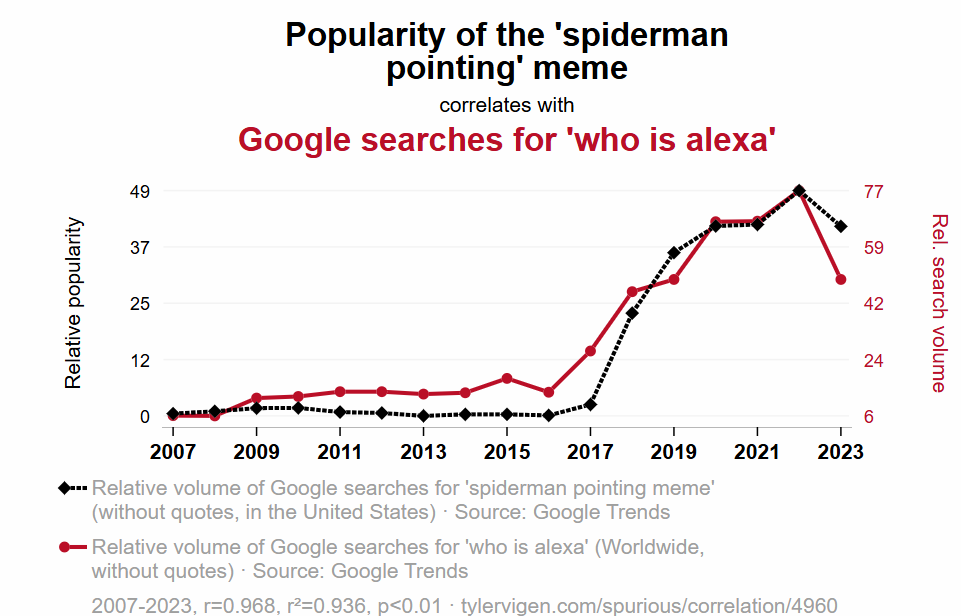


## Basic Method

Data analysis often follows this general method:

1. **Data collection**  
2. **Data cleaning**  
3. **Exploration**  
4. **Model building** (check that your inferences are correct)  
5. **Communicate findings**

You’ll practice each step below using a small dataset.


### Step 1: Data Collection

In [3]:
# Step 1: Load data
data = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv")
data.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


**Questions:**
1. How many rows and columns are in this dataset?
2. What does each column represent?


**Your Answer**
1. There are 5 rows and 5 columns (not counting the headers). 
2. Each column represents a different part of the data, which are the length of the sepal, the width of the sepal, the length of the petal, the width of the petal, and the species. 

### Step 2: Data Cleaning

In [6]:
# Step 2: Clean data
data.info()        # Check for missing values
data.isna().sum()  # Count missing entries

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

 If you find any missing values, you could decide to fill them in with some value that makes sense with the data or just drop any rows with missing values.


In [5]:
# Example:
data = data.dropna()

### Step 3: Exploration

       sepal_length  sepal_width  petal_length  petal_width
count        150.00       150.00        150.00       150.00
mean           5.84         3.06          3.76         1.20
std            0.83         0.44          1.77         0.76
min            4.30         2.00          1.00         0.10
25%            5.10         2.80          1.60         0.30
50%            5.80         3.00          4.35         1.30
75%            6.40         3.30          5.10         1.80
max            7.90         4.40          6.90         2.50


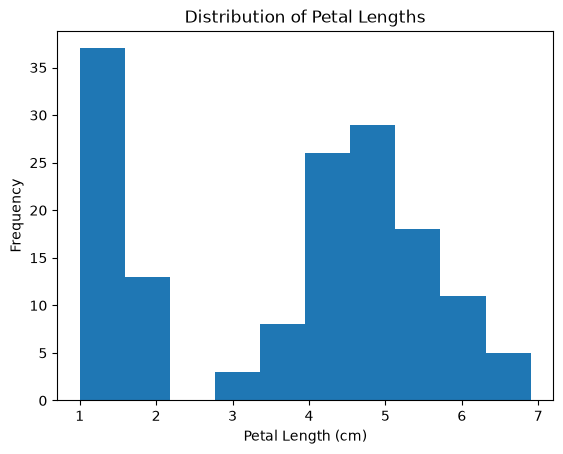

In [8]:
# Step 3: Explore
print(data.describe())

plt.hist(data["petal_length"], bins=10)
plt.title("Distribution of Petal Lengths")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Frequency")
plt.show()

**Questions:**
1. What does the histogram tell you about petal lengths?
2. Are there any visible patterns or clusters?


**Your Answer**
1. The petal lengths vary from 1 cm to 7 cm, and there aren't a lot of petals that are 2.2-2.75ish cm.
2. There is a curve from around 2.75 to 6.9 cm and a peak from 1 to 2.2 cm, which are two clusters. 

## Step 4: Model Building

In [9]:
# Step 4: Build a simple model (group and compare)
avg_lengths = data.groupby("species")["petal_length"].mean()
avg_lengths

species
setosa        1.46
versicolor    4.26
virginica     5.55
Name: petal_length, dtype: float64

**Interpretation:**  
Which species has the longest petals on average?
What conclusion might you draw from this?

**Your Answer**
On average the species with the longest petals is the virginica with an average of 5.55 cm. We can conclude that petal length is a distinct physical trait for each of the species, meaning you may be able to identify the species based on petal length. 

### Step 5: Communicate Findings

Write a short summary of what you discovered.  
Your summary should:
- Include 1–2 sentences describing your data  
- Mention one interesting pattern or comparison  
- Suggest what further data might help improve the analysis  

**Your summary:**
```
Our data demonstrates that the virginica has the longest petals of an average 5.55 cm, the versicolor has an average petal length of 4.26 cm, and the setosa has an average petal length of 1.46 cm, making it the shortest petal length in the dataset. Additionally, based on the petal length distribution, we can see that the lengths around 1-1.5 cm are very common, while 2.2-2.7 cm is not. 

One interesting pattern is that the most common petal length is around 1 cm, which is the length of the setosa species. This may suggest that the sestosa species is the most common. 

Further data that could help improve the analysis would be more data per species, as well as maybe different species. If we can identify a general petal length for each species, we perhaps would be able to measure a petal length to find which species the flower is. 
```


## Important Notes

- Use **statistics**, **plots**, and **grouping** to explore your data and test your ideas.  
- Always question your conclusions — could something else explain the trend?  
- **Data analysis is iterative:** hypothesis → test → conclusion → new hypothesis → …  

### Understanding Significance Levels  
When you analyze data, sometimes you want to know whether your results are **real** or just due to random chance.  
This is where the **significance level** (often written as **α**, alpha) comes in.  

- Common values are **0.05** (5%) or **0.01** (1%).  
- If the probability (called the **p-value**) is *less than α*, your result is considered **statistically significant** — meaning it’s unlikely to have happened by chance.


In [10]:
from scipy import stats

# Example: compare petal lengths between two species
setosa = data[data["species"] == "setosa"]["petal_length"]
versicolor = data[data["species"] == "versicolor"]["petal_length"]

t_stat, p_value = stats.ttest_ind(setosa, versicolor)
print("p-value:", p_value)

if p_value < 0.05:
    print("✅ Significant difference between species!")
else:
    print("❌ No significant difference found.")

p-value: 5.404910513441767e-62
✅ Significant difference between species!


**Questions:**
1. What does the p-value tell you about the two groups?
2. How would increasing or decreasing α (the significance level) change your confidence in the result? Lower α = Higher confidence


**Your Answer**
1. The p-value tells you the probability that the differences between the two groups is by chance. If the p difference is less than 0.05, then we can more conifidentally conclude a real significant difference, rather than lacking data. 

2. An increasing or decreasing significant level would either be decrease and increase your confidnence about the result respectively. If the "barrier" is super low, then if the result manages to pass it, we can be more certain that it is true. 

## Now try it yourself

Try downloading a free dataset from [Kaggle](https://www.kaggle.com/datasets) or another source, and repeat the **five-step method** on your own.  
You can use techniques like:
- `groupby()`
- `.corr()`
- scatter plots or bar charts  

Include **1–2 plots** that support your conclusion.


In [18]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os

# downloading the data
path = kagglehub.dataset_download("larsen0966/penguins")

print("Path to dataset files:", path)

# finding the csv file
csv_files = glob.glob(os.path.join(path, "*.csv"))
data = pd.read_csv(csv_files[0])

# step 1: data collection
data.head()

print("**********************")
# step 2: cleaning the data
data.info()
print(data.isna().sum())
data = data.dropna()

print(data.info())

Path to dataset files: /Users/isabelleqiao/.cache/kagglehub/datasets/larsen0966/penguins/versions/1
**********************
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         344 non-null    int64  
 1   species            344 non-null    str    
 2   island             344 non-null    str    
 3   bill_length_mm     342 non-null    float64
 4   bill_depth_mm      342 non-null    float64
 5   flipper_length_mm  342 non-null    float64
 6   body_mass_g        342 non-null    float64
 7   sex                333 non-null    str    
 8   year               344 non-null    int64  
dtypes: float64(4), int64(2), str(3)
memory usage: 24.3 KB
Unnamed: 0            0
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year 

       Unnamed: 0  bill_length_mm  bill_depth_mm  flipper_length_mm  \
count      333.00          333.00         333.00             333.00   
mean       174.32           43.99          17.16             200.97   
std         98.39            5.47           1.97              14.02   
min          1.00           32.10          13.10             172.00   
25%         90.00           39.50          15.60             190.00   
50%        173.00           44.50          17.30             197.00   
75%        259.00           48.60          18.70             213.00   
max        344.00           59.60          21.50             231.00   

       body_mass_g     year  
count       333.00   333.00  
mean       4207.06  2008.04  
std         805.22     0.81  
min        2700.00  2007.00  
25%        3550.00  2007.00  
50%        4050.00  2008.00  
75%        4775.00  2009.00  
max        6300.00  2009.00  


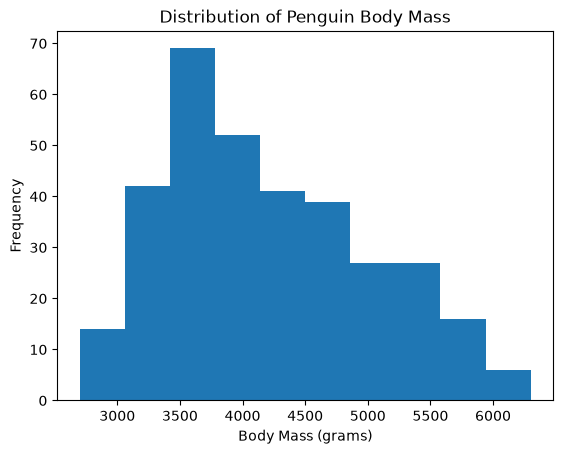

In [19]:
# step 3: explore
print(data.describe())

plt.hist(data["body_mass_g"], bins=10)

plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Body Mass (grams)")
plt.ylabel("Frequency")

plt.show()

In [25]:
# step 4: simple model

avg_measurements = data.groupby("species")[["body_mass_g", "flipper_length_mm"]].mean()

print(avg_measurements)

           body_mass_g  flipper_length_mm
species                                  
Adelie         3706.16             190.10
Chinstrap      3733.09             195.82
Gentoo         5092.44             217.24


In [26]:
# finding the correlation with corr 

correlation = data["body_mass_g"].corr(data["flipper_length_mm"])

print("Correlation:", correlation)

Correlation: 0.872978898565361


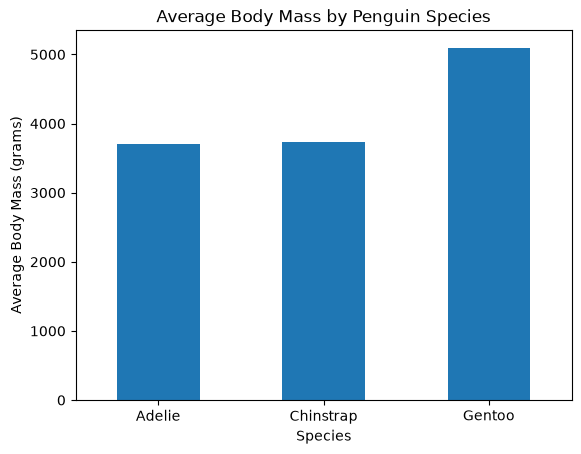

In [27]:
# plot 1: average body mass by species
avg_measurements["body_mass_g"].plot(kind="bar")

plt.title("Average Body Mass by Penguin Species")
plt.xlabel("Species")
plt.ylabel("Average Body Mass (grams)")
plt.xticks(rotation=0)

plt.show()

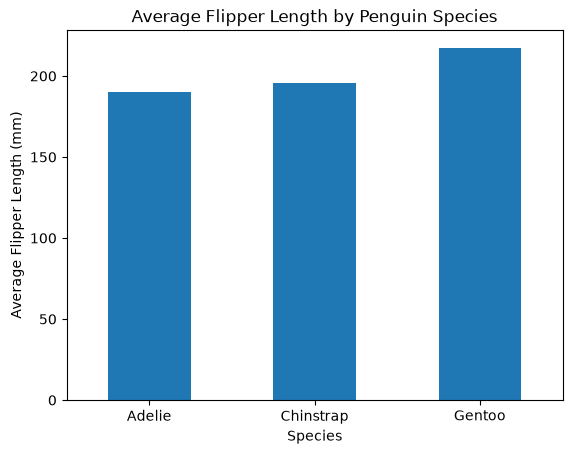

In [28]:
# plot 2: average flipper length by species
avg_measurements["flipper_length_mm"].plot(kind="bar")

plt.title("Average Flipper Length by Penguin Species")
plt.xlabel("Species")
plt.ylabel("Average Flipper Length (mm)")
plt.xticks(rotation=0)

plt.show()

The dataset is from Kaggle and has information about different penguin species (yay penguins)! One pattern I discovered was that different penguin species have different average body masses and flipper lengths, shown in the graphs. We could possibly identify species by these characteristics. 

For further research, we can collect more information about age, diet, habitat, or other environmental conditions to explain why certain penguin species are larger than others. 

## Conclusions

- “Black box” analysis is not useful — you must be able to explain your reasoning. 
    - Intuitions are useful, but they won't convince stakeholders. 
- Only use techniques you understand.  
- Be cautious: **past data doesn’t always predict the future.**  
- This sets the stage for **machine learning** and predictive modeling!
